In [1]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [2]:
# Load the saved model
model = joblib.load('../src/loan_model.pkl')

# Load processed data
df = pd.read_csv('../data/processed_loan_data.csv')

# Recreate the same split as Phase 3
# IMPORTANT: same random_state=42 guarantees identical splits
X = df.drop(columns=['Loan_Status'])
y = df['Loan_Status']

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

# Get predictions on full dataset for bias analysis
y_pred_all = model.predict(X)

print("Predictions generated:", len(y_pred_all))

Predictions generated: 614


In [3]:
# Combine original data with predictions
results_df = X.copy()
results_df['Actual'] = y.values
results_df['Predicted'] = y_pred_all

print("Results dataframe shape:", results_df.shape)
results_df.head()

Results dataframe shape: (614, 13)


,Gender,Married,Dependents,Education,Self_Employed,Loan_Amount_Term,Credit_History,Property_Area,Income_to_Loan_Ratio,Total_Income_Log,LoanAmount_Log,Actual,Predicted
0,1,0,0,1,0,360.0,1.0,2,45.695312,8.674197,4.859812,1,1
1,1,1,1,1,0,360.0,1.0,0,47.585938,8.714732,4.859812,0,1
2,1,1,0,1,1,360.0,1.0,2,45.454545,8.006701,4.204693,1,1
3,1,1,0,0,0,360.0,1.0,2,41.175000,8.505525,4.795791,1,1
4,1,0,0,1,0,360.0,1.0,2,42.553191,8.699681,4.955827,1,1


In [4]:
# Gender: 1 = Male, 0 = Female
gender_analysis = results_df.groupby('Gender').agg(
    Total=('Predicted', 'count'),
    Approved=('Predicted', 'sum'),
    Approval_Rate=('Predicted', 'mean')
).round(4)

gender_analysis.index = gender_analysis.index.map({1: 'Male', 0: 'Female'})
print("=== Approval Rate by Gender ===")
print(gender_analysis)

# Calculate disparity
male_rate = results_df[results_df['Gender'] == 1]['Predicted'].mean()
female_rate = results_df[results_df['Gender'] == 0]['Predicted'].mean()
gender_disparity = abs(male_rate - female_rate)

print(f"\nMale approval rate:   {male_rate:.4f}")
print(f"Female approval rate: {female_rate:.4f}")
print(f"Gender disparity:     {gender_disparity:.4f}")

=== Approval Rate by Gender ===
        Total  Approved  Approval_Rate
Gender                                
Female    112        74         0.6607
Male      502       342         0.6813

Male approval rate:   0.6813
Female approval rate: 0.6607
Gender disparity:     0.0206


In [5]:
married_analysis = results_df.groupby('Married').agg(
    Total=('Predicted', 'count'),
    Approved=('Predicted', 'sum'),
    Approval_Rate=('Predicted', 'mean')
).round(4)

married_analysis.index = married_analysis.index.map({1: 'Married', 0: 'Not Married'})
print("=== Approval Rate by Marital Status ===")
print(married_analysis)

married_rate = results_df[results_df['Married'] == 1]['Predicted'].mean()
single_rate = results_df[results_df['Married'] == 0]['Predicted'].mean()
married_disparity = abs(married_rate - single_rate)

print(f"\nMarried approval rate:     {married_rate:.4f}")
print(f"Not married approval rate: {single_rate:.4f}")
print(f"Marital status disparity:  {married_disparity:.4f}")

=== Approval Rate by Marital Status ===
             Total  Approved  Approval_Rate
Married                                    
Not Married    213       122         0.5728
Married        401       294         0.7332

Married approval rate:     0.7332
Not married approval rate: 0.5728
Marital status disparity:  0.1604


In [6]:
# False Negative = person was actually approved but model denied them
# This is the most harmful bias in lending

def false_negative_rate(group_df):
    actual_pos = group_df[group_df['Actual'] == 1]
    if len(actual_pos) == 0:
        return 0
    fn = actual_pos[actual_pos['Predicted'] == 0]
    return len(fn) / len(actual_pos)

male_df = results_df[results_df['Gender'] == 1]
female_df = results_df[results_df['Gender'] == 0]

male_fnr = false_negative_rate(male_df)
female_fnr = false_negative_rate(female_df)
fnr_disparity = abs(male_fnr - female_fnr)

print("=== False Negative Rate by Gender ===")
print(f"Male FNR:         {male_fnr:.4f}")
print(f"Female FNR:       {female_fnr:.4f}")
print(f"FNR Disparity:    {fnr_disparity:.4f}")

=== False Negative Rate by Gender ===
Male FNR:         0.0893
Female FNR:       0.0933
FNR Disparity:    0.0040


In [7]:
def compute_bias_score(gender_disparity, married_disparity, fnr_disparity):
    """
    Combines three disparity metrics into a single bias score.
    
    Weights:
    - Gender disparity:         40% (protected attribute)
    - FNR disparity:            40% (most harmful error)
    - Marital disparity:        20% (secondary attribute)
    
    Score of 0 = perfectly fair
    Score of 1 = maximum bias
    Threshold > 0.20 = flag for human review
    """
    bias_score = (
        0.40 * gender_disparity +
        0.40 * fnr_disparity +
        0.20 * married_disparity
    )
    return round(bias_score, 4)

bias_score = compute_bias_score(gender_disparity, married_disparity, fnr_disparity)

print("=" * 45)
print(f"  BIAS SCORE:  {bias_score}")
print("=" * 45)

BIAS_THRESHOLD = 0.20

if bias_score > BIAS_THRESHOLD:
    decision = "🚨 FLAG FOR HUMAN REVIEW"
    reason = f"Bias score {bias_score} exceeds threshold {BIAS_THRESHOLD}"
else:
    decision = "✅ CLEARED FOR AUTOMATED EMAIL"
    reason = f"Bias score {bias_score} is within acceptable range"

print(f"\nAgent Decision: {decision}")
print(f"Reason: {reason}")

  BIAS SCORE:  0.0419

Agent Decision: ✅ CLEARED FOR AUTOMATED EMAIL
Reason: Bias score 0.0419 is within acceptable range


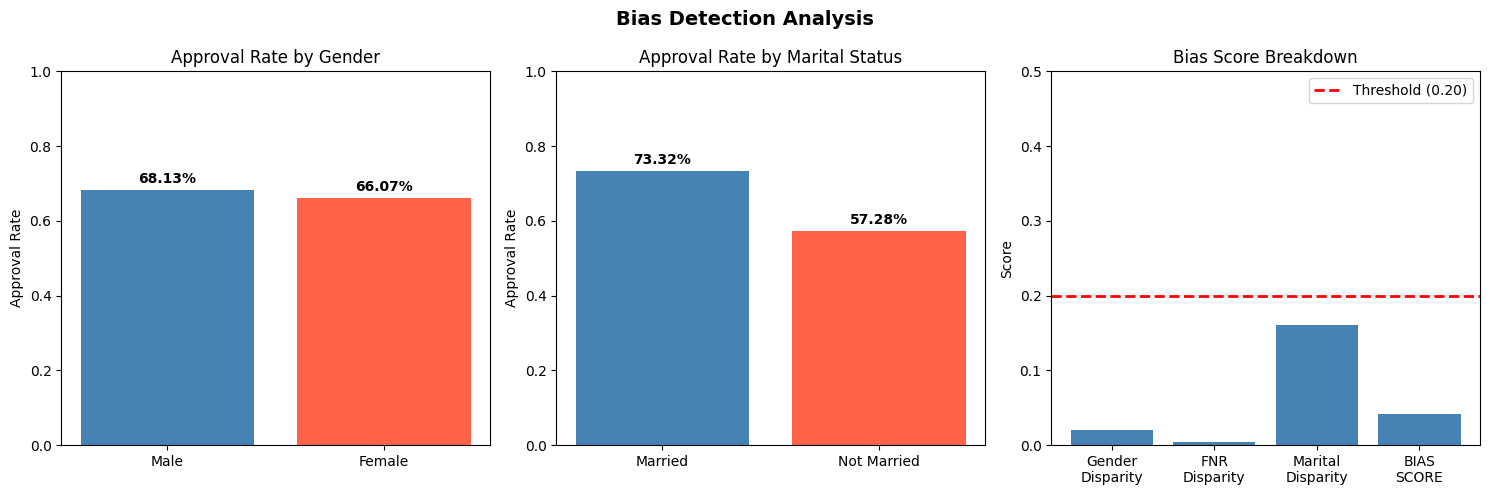

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Plot 1: Approval rate by gender
gender_plot = pd.DataFrame({
    'Group': ['Male', 'Female'],
    'Approval Rate': [male_rate, female_rate]
})
axes[0].bar(gender_plot['Group'], gender_plot['Approval Rate'],
            color=['steelblue', 'tomato'])
axes[0].set_title('Approval Rate by Gender')
axes[0].set_ylabel('Approval Rate')
axes[0].set_ylim(0, 1)
for i, v in enumerate([male_rate, female_rate]):
    axes[0].text(i, v + 0.02, f'{v:.2%}', ha='center', fontweight='bold')

# Plot 2: Approval rate by marital status
married_plot = pd.DataFrame({
    'Group': ['Married', 'Not Married'],
    'Approval Rate': [married_rate, single_rate]
})
axes[1].bar(married_plot['Group'], married_plot['Approval Rate'],
            color=['steelblue', 'tomato'])
axes[1].set_title('Approval Rate by Marital Status')
axes[1].set_ylabel('Approval Rate')
axes[1].set_ylim(0, 1)
for i, v in enumerate([married_rate, single_rate]):
    axes[1].text(i, v + 0.02, f'{v:.2%}', ha='center', fontweight='bold')

# Plot 3: Bias score gauge
categories = ['Gender\nDisparity', 'FNR\nDisparity', 'Marital\nDisparity', 'BIAS\nSCORE']
values = [gender_disparity, fnr_disparity, married_disparity, bias_score]
colors = ['tomato' if v > 0.20 else 'steelblue' for v in values]
axes[2].bar(categories, values, color=colors)
axes[2].axhline(y=0.20, color='red', linestyle='--', linewidth=2, label='Threshold (0.20)')
axes[2].set_title('Bias Score Breakdown')
axes[2].set_ylabel('Score')
axes[2].set_ylim(0, 0.5)
axes[2].legend()

plt.suptitle('Bias Detection Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [10]:
import pandas as pd
import numpy as np
import joblib
import os

BASE_DIR = os.path.abspath('..')

def false_negative_rate(group_df):
    actual_pos = group_df[group_df['Actual'] == 1]
    if len(actual_pos) == 0:
        return 0
    fn = actual_pos[actual_pos['Predicted'] == 0]
    return len(fn) / len(actual_pos)

def compute_bias_score(gender_disparity, married_disparity, fnr_disparity):
    return round(
        0.40 * gender_disparity +
        0.40 * fnr_disparity +
        0.20 * married_disparity, 4
    )

def run_bias_agent(applicant_data: dict, prediction: int) -> dict:
    df = pd.read_csv(os.path.join(BASE_DIR, 'data', 'processed_loan_data.csv'))
    model = joblib.load(os.path.join(BASE_DIR, 'src', 'loan_model.pkl'))

    X = df.drop(columns=['Loan_Status'])
    y = df['Loan_Status']
    y_pred = model.predict(X)

    results = X.copy()
    results['Actual'] = y.values
    results['Predicted'] = y_pred

    male_rate = results[results['Gender'] == 1]['Predicted'].mean()
    female_rate = results[results['Gender'] == 0]['Predicted'].mean()
    gender_disparity = abs(male_rate - female_rate)

    married_rate = results[results['Married'] == 1]['Predicted'].mean()
    single_rate = results[results['Married'] == 0]['Predicted'].mean()
    married_disparity = abs(married_rate - single_rate)

    male_fnr = false_negative_rate(results[results['Gender'] == 1])
    female_fnr = false_negative_rate(results[results['Gender'] == 0])
    fnr_disparity = abs(male_fnr - female_fnr)

    bias_score = compute_bias_score(gender_disparity, married_disparity, fnr_disparity)
    BIAS_THRESHOLD = 0.20
    needs_review = bias_score > BIAS_THRESHOLD

    return {
        "bias_score": bias_score,
        "needs_human_review": needs_review,
        "decision": "FLAG FOR HUMAN REVIEW" if needs_review else "CLEARED",
        "reason": f"Bias score {bias_score} {'exceeds' if needs_review else 'within'} threshold {BIAS_THRESHOLD}",
        "metrics": {
            "gender_disparity": round(gender_disparity, 4),
            "married_disparity": round(married_disparity, 4),
            "fnr_disparity": round(fnr_disparity, 4),
            "male_approval_rate": round(male_rate, 4),
            "female_approval_rate": round(female_rate, 4)
        }
    }